[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/oscardasilva0/mestrado_censo_reduzido/blob/master/ml%20_2010.ipynb)

## Preparação dos dados
### Carrega arquivo

In [1]:
import os
import pandas as pd
import numpy as np

# Carrega arquivo local ou direto do GitHub caso esteja em ambiente virtual (ex.: Google Colab)
caminho_arquivo = "salvador_2010.csv"
url_git = "https://github.com/oscardasilva0/mestrado_censo_reduzido/blob/master/salvador_2010.csv?raw=true"
dados_censo = pd.read_csv(caminho_arquivo if os.path.exists(caminho_arquivo) else url_git)
dados_censo

,code_muni,code_state,abbrev_state,name_state,code_region,name_region,code_weighting,V0001,V0002,V0011,...,M0218,M0219,M0220,M0221,M0222,M0301,M0401,M0402,M0701,V1005
0,2927408,29,BA,Bahia,2,Nordeste,2927408005001,29,27408,2927408005001,...,2,2,2,2,2,2,2,2,2,1
1,2927408,29,BA,Bahia,2,Nordeste,2927408005001,29,27408,2927408005001,...,2,2,2,2,2,2,2,2,2,1
2,2927408,29,BA,Bahia,2,Nordeste,2927408005001,29,27408,2927408005001,...,2,2,2,2,2,2,2,2,2,1
3,2927408,29,BA,Bahia,2,Nordeste,2927408005001,29,27408,2927408005001,...,2,2,2,2,2,2,2,2,2,1
4,2927408,29,BA,Bahia,2,Nordeste,2927408005001,29,27408,2927408005001,...,2,2,2,2,2,2,2,2,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44497,2927408,29,BA,Bahia,2,Nordeste,2927408005062,29,27408,2927408005062,...,2,2,2,2,2,2,2,2,2,1
44498,2927408,29,BA,Bahia,2,Nordeste,2927408005062,29,27408,2927408005062,...,2,2,2,2,2,2,2,2,2,1
44499,2927408,29,BA,Bahia,2,Nordeste,2927408005062,29,27408,2927408005062,...,2,2,2,2,2,2,2,2,2,1
44500,2927408,29,BA,Bahia,2,Nordeste,2927408005062,29,27408,2927408005062,...,2,2,2,2,2,2,2,1,2,1


In [ ]:
## renomeia as variaveis

#renomeado para facilitar a analise. Foi utilizado o dicionario de dados que esta na raiz do projeto
dados_censo.rename(
    columns={
        'code_muni': 'code_muni',
        'code_state': 'code_state',
        'abbrev_state': 'abbrev_state',
        'name_state': 'name_state',
        'code_region': 'code_region',
        'name_region': 'name_region',
        'code_weighting': 'code_weighting',
        'V0001': 'uf_V0101', # 'MG, AC, RO ...'
        'V0002': 'code_muni_V0002', #
        'V0011': 'AREAP_V0011', #ÁREA DE PONDERAÇÃO
        'V0300': 'CONTROLE_V0300',
        'V0010': 'peso_V0010', #PESO AMOSTRAL
        'V1001': 'regiao_V1001', # norte, nordeste
        'V1002': 'mesoregiao_V1002', 
        'V1003': 'microregiao_V1003',
        'V1004': 'cod_regiao_metropolitana_V1004', #CÓDIGO DA REGIÃO METROPOLITANA:
        'V1006': 'situacao_domicilio_V1006', # 1 – Urbano, 2 – Rural
        'V4001': 'especie_dom_V4001', # 01- Domicílio particular permanente ocupado 
        'V4002': 'tipo_esp_V4002', # 11- Casa, 12- Casa de vila ou em condomínio
        'V0201': 'condicao_oculpacao_V0201', # 1- Próprio de algum morador - já pago
        'V2011': 'v_alugel_V2011', # VALOR DO ALUGUEL (EM REAIS)             
        'V2012': 'v_alugel_sal_V2012', # ALUGUEL EM Nº DE SALÁRIOS MÍNIMOS 
        'V0202': 'mat_paredes_V0202', # 1- Alvenaria com revestimento 2- Alvenaria sem revestimento
        'V0203': 'n_comodos_V0203', # CÔMODOS, NÚMERO: - Branco - 1 a 30
        'V6203': 'densidade_moradores_comodo__V6203', # DENSIDADE DE MORADOR / DORMITÓRIO 
        'V0204': 'n_dormitorios_V0204', # DENSIDADE DE MORADOR/CÔMODO         
        'V6204': 'densidade_moradores_dormitorios_V6204', # CÔMODOS COMO DORMITÓRIO, NÚMERO: 1 a 15
        'V0205': 'n_banheiros_V0205', #BANHEIROS DE USO EXCLUSIVO, NÚMERO:  0 a 9
        'V0206': 'existe_sanitario_V0206',  ##1 – Sim 2 - Nao Branco
        'V0207': 'esgoto_V0207', #1 - Rede geral de esgoto ou pluvial , 2- Fossa séptica ...
        'V0208': 'agua_origem_V0208', # 01- Rede geral de distribuição 02- Poço ou nascente na propriedade
        'V0209': 'agua_canalizada_V0209', # 1- Sim, em pelo menos um cômodo
        'V0210': 'lixo_V0210', # 1- Coletado diretamente por serviço de limpeza
        'V0211': 'energia_V0211', # 1- Sim, de companhia distribuidora
        'V0212': 'energia_relogio_V0212',# 1- Sim, de uso exclusivo 2- Sim, de uso comum 
        'V0213': 'radio_V0213',  #1 – Sim 2 - Nao, Branco
        'V0214': 'tv_V0214', #1 – Sim 2 - Nao, Branco
        'V0215': 'maquina_lavar_roupa_V0215', #1 – Sim 2 - Nao, Branco
        'V0216': 'geladeira_V0216', #1 – Sim 2 - Nao, Branco
        'V0217': 'cel_V0217', #1 – Sim 2 - Nao, Branco
        'V0218': 'tel_V0218', #1 – Sim 2 - Nao, Branco
        'V0219': 'pc_V0219', #1 – Sim 2 - Nao, Branco
        'V0220': 'pc_net_V0220', #1 – Sim 2 - Nao, Branco
        'V0221': 'moto_V0221', #1 – Sim 2 - Nao, Branco
        'V0222': 'carro_V0222', #1 – Sim 2 - Nao, Branco
        'V0301': 'pessoa_exterior_V0301', # ALGUMA PESSOA QUE MORAVA COM VOCÊ(S) ESTAVA MORANDO EM OUTRO PAÍS EM 31 DE JULHO DE 2010: 1 – Sim 2 - Nao, Branco
        'V0401': 'n_moradores_V0401',
        'V0402': 'n_responsaveis_V0402', # 1- Apenas um morador..
        'V0701': 'n_mortos_ano_V0701',
        'V6529': 'renda_V6529', # RENDIMENTO MENSAL DOMICILIAR EM JULHO DE 2010 
        'V6530': 'renda_sal_V6530', # RENDIMENTO DOMICILIAR, SALÁRIOS MÍNIMOS, EM JULHO DE 2010 
        'V6531': 'renda_percapita_V6531', # RENDIMENTO DOMICILIAR PER CAPITA EM JULHO DE 2010 
        'V6532': 'renda_percapita_sal_V6532', # RENDIMENTO DOMICILIAR PER CAPITA, EM Nº DE SALÁRIOS MÍNIMOS, EM JULHO DE 2010 
        'V6600': 'esp_uni_domes_V6600', # Espécie da Unidade Doméstica 1- Unipessoal
        'V6210': 'adequacao_moradia_V6210', # ADEQUAÇÃO DA MORADIA 1- 	Adequada 2- 	Semi-adequada ..
        'M0201': '_M0201', # MARCA DE IMPUTAÇÃO
        'M2011': '_M2011', # MARCA DE IMPUTAÇÃO
        'M0202': '_M0202', # MARCA DE IMPUTAÇÃO
        'M0203': '_M0203', # MARCA DE IMPUTAÇÃO
        'M0204': '_M0204', # MARCA DE IMPUTAÇÃO
        'M0205': '_M0205', # MARCA DE IMPUTAÇÃO
        'M0206': '_M0206', # MARCA DE IMPUTAÇÃO
        'M0207': '_M0207', # MARCA DE IMPUTAÇÃO
        'M0208': '_M0208', # MARCA DE IMPUTAÇÃO
        'M0209': '_M0209', # MARCA DE IMPUTAÇÃO
        'M0210': '_M0210', # MARCA DE IMPUTAÇÃO
        'M0211': '_M0211', # MARCA DE IMPUTAÇÃO
        'M0212': '_M0212', # MARCA DE IMPUTAÇÃO
        'M0213': '_M0213', # MARCA DE IMPUTAÇÃO
        'M0214': '_M0214', # MARCA DE IMPUTAÇÃO
        'M0215': '_M0215', # MARCA DE IMPUTAÇÃO
        'M0216': '_M0216', # MARCA DE IMPUTAÇÃO
        'M0217': '_M0217', # MARCA DE IMPUTAÇÃO
        'M0218': '_M0218', # MARCA DE IMPUTAÇÃO
        'M0219': '_M0219', # MARCA DE IMPUTAÇÃO
        'M0220': '_M0220', # MARCA DE IMPUTAÇÃO
        'M0221': '_M0221', # MARCA DE IMPUTAÇÃO
        'M0222': '_M0222', # MARCA DE IMPUTAÇÃO
        'M0301': '_M0301', # MARCA DE IMPUTAÇÃO
        'M0401': '_M0401', # MARCA DE IMPUTAÇÃO
        'M0402': '_M0402', # MARCA DE IMPUTAÇÃO
        'M0701': '_M0701', # MARCA DE IMPUTAÇÃO
        'V1005': 'situacao_setor_V1005',  # Situação do setor 1 - Área urbanizada 2 - Área não urbanizada 3 - Área urbanizada isolada
    }, inplace= True
)

dados_censo.columns




<positron-console-cell-2>:4: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


Index(['code_muni', 'code_state', 'abbrev_state', 'name_state', 'code_region',
       'name_region', 'code_weighting', 'uf_V0101', 'code_muni_V0002',
       'AREAP_V0011', 'CONTROLE_V0300', 'peso_V0010', 'regiao_V1001',
       'mesoregiao_V1002', 'microregiao_V1003',
       'cod_regiao_metropolitana_V1004', 'situacao_domicilio_V1006',
       'especie_dom_V4001', 'tipo_esp_V4002', 'condicao_oculpacao_V0201',
       'v_alugel_V2011', 'v_alugel_sal_V2012', 'mat_paredes_V0202',
       'n_comodos_V0203', 'densidade_moradores_comodo__V6203',
       'n_dormitorios_V0204', 'densidade_moradores_dormitorios_V6204',
       'n_banheiros_V0205', 'existe_sanitario_V0206', 'esgoto_V0207',
       'agua_origem_V0208', 'agua_canalizada_V0209', 'lixo_V0210',
       'energia_V0211', 'energia_relogio_V0212', 'radio_V0213', 'tv_V0214',
       'maquina_lavar_roupa_V0215', 'geladeira_V0216', 'cel_V0217',
       'tel_V0218', 'pc_V0219', 'pc_net_V0220', 'moto_V0221', 'carro_V0222',
       'pessoa_exterior_V0301

### Forçando tipagem
Os valores que estão comentados são itens que possui nulos e estão apresentado erro ao tipar sem fazer o tratamento  


In [3]:
dados_censo.info()

<class 'pandas.DataFrame'>
RangeIndex: 44502 entries, 0 to 44501
Data columns (total 83 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   code_muni                              44502 non-null  int64  
 1   code_state                             44502 non-null  int64  
 2   abbrev_state                           44502 non-null  str    
 3   name_state                             44502 non-null  str    
 4   code_region                            44502 non-null  int64  
 5   name_region                            44502 non-null  str    
 6   code_weighting                         44502 non-null  int64  
 7   uf_V0101                               44502 non-null  int64  
 8   code_muni_V0002                        44502 non-null  int64  
 9   AREAP_V0011                            44502 non-null  int64  
 10  CONTROLE_V0300                         44502 non-null  int64  
 11  peso_V0010   

In [ ]:
#tipar as colunas
df = dados_censo.copy()
df['code_muni'] = dados_censo['code_muni'].astype({'code_muni': 'category'})
df['code_state'] = dados_censo['code_state'].astype({'code_state': 'category'})
df['abbrev_state'] = dados_censo['abbrev_state'].astype({'abbrev_state': 'category'})
df['name_state'] = dados_censo['name_state'].astype({'name_state': 'category'})
df['code_region'] = dados_censo['code_region'].astype({'code_region': 'category'})
df['name_region'] = dados_censo['name_region'].astype({'name_region': 'category'})
df['code_weighting'] = dados_censo['code_weighting'].astype({'code_weighting': 'category'})
df['uf_V0101'] = dados_censo['uf_V0101'].astype({'uf_V0101': 'category'}) # 'MG, AC, RO ...'
df['code_muni_V0002'] = dados_censo['code_muni_V0002'].astype({'code_muni_V0002': 'category'}) #
df['AREAP_V0011'] = dados_censo['AREAP_V0011'].astype({'AREAP_V0011': 'category'}) #ÁREA DE PONDERAÇÃO
df['CONTROLE_V0300'] = dados_censo['CONTROLE_V0300'].astype({'CONTROLE_V0300': 'category'})
df['peso_V0010'] = dados_censo['peso_V0010'].astype({'peso_V0010': np.int64}) #PESO AMOSTRAL
df['regiao_V1001'] = dados_censo['regiao_V1001'].astype({'regiao_V1001': 'category'}) # norte, nordeste
df['mesoregiao_V1002'] = dados_censo['mesoregiao_V1002'].astype({'mesoregiao_V1002': 'category'}) 
df['microregiao_V1003'] = dados_censo['microregiao_V1003'].astype({'microregiao_V1003': 'category'})
df['cod_regiao_metropolitana_V1004'] = dados_censo['cod_regiao_metropolitana_V1004'].astype({'cod_regiao_metropolitana_V1004': 'category'}) #CÓDIGO DA REGIÃO METROPOLITANA:
df['situacao_domicilio_V1006'] = dados_censo['situacao_domicilio_V1006'].astype({'situacao_domicilio_V1006': 'category'}) # 1 – Urbano, 2 – Rural
df['especie_dom_V4001'] = dados_censo['especie_dom_V4001'].astype({'especie_dom_V4001': 'category'}) # 01- Domicílio particular permanente ocupado 
df['tipo_esp_V4002'] = dados_censo['tipo_esp_V4002'].astype({'tipo_esp_V4002': 'category'}) # 11- Casa, 12- Casa de vila ou em condomínio
df['condicao_oculpacao_V0201'] = dados_censo['condicao_oculpacao_V0201'].astype({'condicao_oculpacao_V0201': 'category'}) # 1- Próprio de algum morador - já pago
df['v_alugel_V2011'] = dados_censo['v_alugel_V2011'].astype({'v_alugel_V2011': 'float'}) # VALOR DO ALUGUEL (EM REAIS)             
df['v_alugel_sal_V2012'] = dados_censo['v_alugel_sal_V2012'].astype({'v_alugel_sal_V2012': 'float'}) # ALUGUEL EM Nº DE SALÁRIOS MÍNIMOS 

df['mat_paredes_V0202'] = dados_censo['mat_paredes_V0202'].astype({'mat_paredes_V0202': 'category'}) # 1- Alvenaria com revestimento 2- Alvenaria sem revestimento
# df['n_comodos_V0203'] = dados_censo['n_comodos_V0203'].astype({'n_comodos_V0203': np.int64}) # CÔMODOS, NÚMERO: - Branco - 1 a 30
# df['densidade_moradores_comodo__V6203'] = dados_censo['densidade_moradores_comodo__V6203'].astype({'densidade_moradores_comodo__V6203',  np.int64}) # DENSIDADE DE MORADOR/CÔMODO 

# df['n_dormitorios_V0204'] = dados_censo['n_dormitorios_V0204'].astype({'n_dormitorios_V0204',  np.int64}) 
# df['densidade_moradores_dormitorios_V6204'] = dados_censo['densidade_moradores_dormitorios_V6204'].astype({'densidade_moradores_dormitorios_V6204',  np.int64}) # DENSIDADE DE MORADOR / DORMITÓRIO  
# df['n_banheiros_V0205'] = dados_censo['n_banheiros_V0205'].astype({'n_banheiros_V0205',  np.int64}) #BANHEIROS DE USO EXCLUSIVO, NÚMERO:  0 a 9
df['existe_sanitario_V0206'] = dados_censo['existe_sanitario_V0206'].astype({'existe_sanitario_V0206': 'category'})  ##1 – Sim 2 - Nao Branco
df['esgoto_V0207'] = dados_censo['esgoto_V0207'].astype({'esgoto_V0207': 'category'}) #1 - Rede geral de esgoto ou pluvial , 2- Fossa séptica ...
df['agua_origem_V0208'] = dados_censo['agua_origem_V0208'].astype({'agua_origem_V0208': 'category'}) # 01- Rede geral de distribuição 02- Poço ou nascente na propriedade
df['agua_canalizada_V0209'] = dados_censo['agua_canalizada_V0209'].astype({'agua_canalizada_V0209': 'category'}) # 1- Sim, em pelo menos um cômodo
df['lixo_V0210'] = dados_censo['lixo_V0210'].astype({'lixo_V0210': 'category'}) # 1- Coletado diretamente por serviço de limpeza
df['energia_V0211'] = dados_censo['energia_V0211'].astype({'energia_V0211': 'category'}) # 1- Sim, de companhia distribuidora
df['energia_relogio_V0212'] = dados_censo['energia_relogio_V0212'].astype({'energia_relogio_V0212': 'category'})# 1- Sim, de uso exclusivo 2- Sim, de uso comum 
df['radio_V0213'] = dados_censo['radio_V0213'].astype({'radio_V0213': 'category'})  #1 – Sim 2 - Nao, Branco
df['tv_V0214'] = dados_censo['tv_V0214'].astype({'tv_V0214': 'category'}) #1 – Sim 2 - Nao, Branco
df['maquina_lavar_roupa_V0215'] = dados_censo['maquina_lavar_roupa_V0215'].astype({'maquina_lavar_roupa_V0215': 'category'}) #1 – Sim 2 - Nao, Branco
df['geladeira_V0216'] = dados_censo['geladeira_V0216'].astype({'geladeira_V0216': 'category'}) #1 – Sim 2 - Nao, Branco
df['cel_V0217'] = dados_censo['cel_V0217'].astype({'cel_V0217': 'category'}) #1 – Sim 2 - Nao, Branco
df['tel_V0218'] = dados_censo['tel_V0218'].astype({'tel_V0218': 'category'}) #1 – Sim 2 - Nao, Branco
df['pc_V0219'] = dados_censo['pc_V0219'].astype({'pc_V0219': 'category'}) #1 – Sim 2 - Nao, Branco
df['pc_net_V0220'] = dados_censo['pc_net_V0220'].astype({'pc_net_V0220': 'category'}) #1 – Sim 2 - Nao, Branco
df['moto_V0221'] = dados_censo['moto_V0221'].astype({'moto_V0221': 'category'}) #1 – Sim 2 - Nao, Branco
df['carro_V0222'] = dados_censo['carro_V0222'].astype({'carro_V0222': 'category'}) #1 – Sim 2 - Nao, Branco
df['pessoa_exterior_V0301'] = dados_censo['pessoa_exterior_V0301'].astype({'pessoa_exterior_V0301': 'category'}) # ALGUMA PESSOA QUE MORAVA COM VOCÊ(S) ESTAVA MORANDO EM OUTRO PAÍS EM 31 DE JULHO DE 2010: 1 – Sim 2 - Nao, Branco
df['n_moradores_V0401'] = dados_censo['n_moradores_V0401'].astype({'n_moradores_V0401': np.int64})
# df['n_responsaveis_V0402'] = dados_censo['n_responsaveis_V0402'].astype({'n_responsaveis_V0402': np.int64}) # 1- Apenas um morador..
# df['n_mortos_ano_V0701'] = dados_censo['n_mortos_ano_V0701'].astype({'n_mortos_ano_V0701': np.int64})
df['renda_V6529'] = dados_censo['renda_V6529'].astype({'renda_V6529': 'float'}) # RENDIMENTO MENSAL DOMICILIAR EM JULHO DE 2010 
df['renda_sal_V6530'] = dados_censo['renda_sal_V6530'].astype({'renda_sal_V6530': 'float'}) # RENDIMENTO DOMICILIAR, SALÁRIOS MÍNIMOS, EM JULHO DE 2010 
df['renda_percapita_V6531'] = dados_censo['renda_percapita_V6531'].astype({'renda_percapita_V6531': 'float'}) # RENDIMENTO DOMICILIAR PER CAPITA EM JULHO DE 2010 
df['renda_percapita_sal_V6532'] = dados_censo['renda_percapita_sal_V6532'].astype({'renda_percapita_sal_V6532': 'float'}) # RENDIMENTO DOMICILIAR PER CAPITA, EM Nº DE SALÁRIOS MÍNIMOS, EM JULHO DE 2010 
df['esp_uni_domes_V6600'] = dados_censo['esp_uni_domes_V6600'].astype({'esp_uni_domes_V6600': 'category'}) # Espécie da Unidade Doméstica 1- Unipessoal
df['adequacao_moradia_V6210'] = dados_censo['adequacao_moradia_V6210'].astype({'adequacao_moradia_V6210': 'category'}) # ADEQUAÇÃO DA MORADIA 1- 	Adequada 2- 	Semi-adequada ..
df['_M0201'] = dados_censo['_M0201'].astype({'_M0201': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M2011'] = dados_censo['_M2011'].astype({'_M2011': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0202'] = dados_censo['_M0202'].astype({'_M0202': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0203'] = dados_censo['_M0203'].astype({'_M0203': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0204'] = dados_censo['_M0204'].astype({'_M0204': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0205'] = dados_censo['_M0205'].astype({'_M0205': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0206'] = dados_censo['_M0206'].astype({'_M0206': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0207'] = dados_censo['_M0207'].astype({'_M0207': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0208'] = dados_censo['_M0208'].astype({'_M0208': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0209'] = dados_censo['_M0209'].astype({'_M0209': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0210'] = dados_censo['_M0210'].astype({'_M0210': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0211'] = dados_censo['_M0211'].astype({'_M0211': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0212'] = dados_censo['_M0212'].astype({'_M0212': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0213'] = dados_censo['_M0213'].astype({'_M0213': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0214'] = dados_censo['_M0214'].astype({'_M0214': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0215'] = dados_censo['_M0215'].astype({'_M0215': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0216'] = dados_censo['_M0216'].astype({'_M0216': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0217'] = dados_censo['_M0217'].astype({'_M0217': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0218'] = dados_censo['_M0218'].astype({'_M0218': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0219'] = dados_censo['_M0219'].astype({'_M0219': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0220'] = dados_censo['_M0220'].astype({'_M0220': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0221'] = dados_censo['_M0221'].astype({'_M0221': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0222'] = dados_censo['_M0222'].astype({'_M0222': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0301'] = dados_censo['_M0301'].astype({'_M0301': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0401'] = dados_censo['_M0401'].astype({'_M0401': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0402'] = dados_censo['_M0402'].astype({'_M0402': 'category'}) # MARCA DE IMPUTAÇÃO
df['_M0701'] = dados_censo['_M0701'].astype({'_M0701': 'category'}) # MARCA DE IMPUTAÇÃO
df['situacao_setor_V1005'] = dados_censo['situacao_setor_V1005'].astype({'situacao_setor_V1005': 'category'})  # Situação do setor 1 - Área urbanizada 2 - Área não urbanizada 3 - Área urbanizada isolada



## Tratamento da base

In [5]:
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44502 entries, 0 to 44501
Data columns (total 83 columns):
 #   Column                                 Non-Null Count  Dtype   
---  ------                                 --------------  -----   
 0   code_muni                              44502 non-null  category
 1   code_state                             44502 non-null  category
 2   abbrev_state                           44502 non-null  category
 3   name_state                             44502 non-null  category
 4   code_region                            44502 non-null  category
 5   name_region                            44502 non-null  category
 6   code_weighting                         44502 non-null  category
 7   uf_V0101                               44502 non-null  category
 8   code_muni_V0002                        44502 non-null  category
 9   AREAP_V0011                            44502 non-null  category
 10  CONTROLE_V0300                         44502 non-null  category
 11  

As seguintes variaveis precisam de tratamento:
- condicao_oculpacao_V0201;
- v_alugel_V2011;
- v_alugel_sal_V2012;
- mat_paredes_V0202;
- n_comodos_V0203;
- densidade_moradores_comodo__V6203;
- n_dormitorios_V0204;
- densidade_moradores_dormitorios_V6204  43889 non-null  float64 ;
- n_banheiros_V0205;
- existe_sanitario_V0206;
- esgoto_V0207;
- agua_origem_V0208;
- agua_canalizada_V0209;
- lixo_V0210;
- energia_V0211;
- energia_relogio_V0212;
- radio_V0213;
- tv_V0214;
- maquina_lavar_roupa_V0215;
- geladeira_V0216;
- cel_V0217;
- tel_V0218;
- pc_V0219;
- pc_net_V0220;
- moto_V0221;
- carro_V0222;
- pessoa_exterior_V0301;
- n_responsaveis_V0402;
- n_mortos_ano_V0701;
- renda_V6529;
- renda_sal_V6530;
- renda_percapita_V6531;
- renda_percapita_sal_V6532;
- esp_uni_domes_V6600;
- adequacao_moradia_V6210;



Soluções propostas:
Remoção de linhas que possuem renda_V7616 ou renda_sal_V7617 nulo, por se tratar da varaivel respostas.

In [6]:
df.dropna(subset=['renda_V6529'], inplace= True)
df.info()

<class 'pandas.DataFrame'>
Index: 44049 entries, 0 to 44501
Data columns (total 83 columns):
 #   Column                                 Non-Null Count  Dtype   
---  ------                                 --------------  -----   
 0   code_muni                              44049 non-null  category
 1   code_state                             44049 non-null  category
 2   abbrev_state                           44049 non-null  category
 3   name_state                             44049 non-null  category
 4   code_region                            44049 non-null  category
 5   name_region                            44049 non-null  category
 6   code_weighting                         44049 non-null  category
 7   uf_V0101                               44049 non-null  category
 8   code_muni_V0002                        44049 non-null  category
 9   AREAP_V0011                            44049 non-null  category
 10  CONTROLE_V0300                         44049 non-null  category
 11  peso_

<positron-console-cell-6>:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


Pensamento - Valores que ainda possuem nulos:
- condicao_oculpacao_V0201;
- **v_alugel_V2011**;
- **v_alugel_sal_V2012**;
- mat_paredes_V0202;
- n_comodos_V0203;
- densidade_moradores_comodo__V6203;
- n_dormitorios_V0204;
- densidade_moradores_dormitorios_V6204
- n_banheiros_V0205;
- **existe_sanitario_V0206**;
- **esgoto_V0207**;
- agua_origem_V0208;
- agua_canalizada_V0209;
- lixo_V0210;
- energia_V0211;
- **energia_relogio_V0212**;
- radio_V0213;
- tv_V0214;
- maquina_lavar_roupa_V0215;
- geladeira_V0216;
- cel_V0217;
- tel_V0218;
- pc_V0219;
- **pc_net_V0220**;
- moto_V0221;
- carro_V0222;
- adequacao_moradia_V6210;


Pensamento - Checagem da variabilidade dos dados contidos:

- **v_alugel_V2011**;
- **v_alugel_sal_V2012**;
- **existe_sanitario_V0206**;
- **esgoto_V0207**;
- **energia_relogio_V0212**;
- **pc_net_V0220**;


In [7]:
df[['v_alugel_V2011', 'v_alugel_sal_V2012', 'existe_sanitario_V0206', 'esgoto_V0207', 'energia_relogio_V0212', 'pc_net_V0220']].info()

<class 'pandas.DataFrame'>
Index: 44049 entries, 0 to 44501
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   v_alugel_V2011          8648 non-null   float64 
 1   v_alugel_sal_V2012      8648 non-null   float64 
 2   existe_sanitario_V0206  643 non-null    category
 3   esgoto_V0207            43664 non-null  category
 4   energia_relogio_V0212   43378 non-null  category
 5   pc_net_V0220            19963 non-null  category
dtypes: category(4), float64(2)
memory usage: 1.2 MB


Soluções propostas:
- optou-se pela remoção existe_sanitario_V0206 por possuir grande numeros de valores nulos;
- outro ponto e que as informações contidas em 'n_banheiros_V0205' tem altao correlação com 'existe_sanitario_V0210';

In [8]:
df[(df['existe_sanitario_V0206'] == 2) & (df['n_banheiros_V0205'] > 0)] [['existe_sanitario_V0206','n_banheiros_V0205']].head()



,existe_sanitario_V0206,n_banheiros_V0205


In [9]:
df.drop(columns=['existe_sanitario_V0206'], inplace= True)

<positron-console-cell-9>:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


Soluções propostas:
- Optou-se pela  remoção das variaveis '_M0201 ','_M2011','_M0202','_M0203','_M0204','_M0205','_M0206','_M0207','_M0208','_M0209','_M0210','_M0211','_M0212','_M0213','_M0214','_M0215','_M0216','_M0217','_M0218','_M0219','_M0220','_M0221','_M0222','_M0301','_M0401','_M0402','_M0701'. Pois elas são marcadores do ibge que indicam se ouve imputadação do dado.

In [10]:
df[['_M0201','_M2011','_M0202','_M0203','_M0204','_M0205','_M0206','_M0207','_M0208','_M0209','_M0210','_M0211','_M0212','_M0213','_M0214','_M0215','_M0216','_M0217','_M0218','_M0219','_M0220','_M0221','_M0222','_M0301','_M0401','_M0402','_M0701']].value_counts()

_M0201  _M2011  _M0202  _M0203  _M0204  _M0205  _M0206  _M0207  _M0208  _M0209  _M0210  _M0211  _M0212  _M0213  _M0214  _M0215  _M0216  _M0217  _M0218  _M0219  _M0220  _M0221  _M0222  _M0301  _M0401  _M0402  _M0701
2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2         35291
                                                                                                                                                                                                        1       2          3834
                                1       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       2       1       2          2670
                                                                                                                 

In [11]:
df.drop(columns=['_M0201','_M2011','_M0202','_M0203','_M0204','_M0205','_M0206','_M0207','_M0208','_M0209','_M0210','_M0211','_M0212','_M0213','_M0214','_M0215','_M0216','_M0217','_M0218','_M0219','_M0220','_M0221','_M0222','_M0301','_M0401','_M0402','_M0701'], inplace=True)

<positron-console-cell-11>:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


- **v_alugel_V2011**;
- **v_alugel_sal_V2012**;
- **esgoto_V0207**;
- **energia_relogio_V0212**;
- **pc_net_V0220**;

In [12]:
df['v_alugel_V2011'].describe()

count    8648.000000
mean      384.994565
std       324.058731
min         1.000000
25%       200.000000
50%       300.000000
75%       470.000000
max      6000.000000
Name: v_alugel_V2011, dtype: float64

Soluções propostas:
- E para 'v_alugel_V2011', 'v_alugel_sal_V2012', valor vai ser colocado como zero;
Obs.: Penso em remover essa varivél pelo percentual de respotas ser baixo é por não  opção no correlacionada no ano 2000

In [13]:
df[["v_alugel_V2011", "v_alugel_sal_V2012"]] = df[
    ["v_alugel_V2011", "v_alugel_sal_V2012"]
].fillna(0)

In [14]:

df.info()

<class 'pandas.DataFrame'>
Index: 44049 entries, 0 to 44501
Data columns (total 55 columns):
 #   Column                                 Non-Null Count  Dtype   
---  ------                                 --------------  -----   
 0   code_muni                              44049 non-null  category
 1   code_state                             44049 non-null  category
 2   abbrev_state                           44049 non-null  category
 3   name_state                             44049 non-null  category
 4   code_region                            44049 non-null  category
 5   name_region                            44049 non-null  category
 6   code_weighting                         44049 non-null  category
 7   uf_V0101                               44049 non-null  category
 8   code_muni_V0002                        44049 non-null  category
 9   AREAP_V0011                            44049 non-null  category
 10  CONTROLE_V0300                         44049 non-null  category
 11  peso_

- **esgoto_V0207**;
- **energia_relogio_V0212**;
- **pc_net_V0220**;

Solução Proposta:
- Para esgoto_V0207 vai se adotar o preenchimento do valor faltante com um valor proximo;

In [15]:
df["esgoto_V0207"] = df.groupby("code_weighting")["esgoto_V0207"].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else np.nan)
)

Solução Proposta:
- Removação de variaveis de apontamento geografico;

In [16]:
df.drop(columns=[ 'code_muni', 'code_state', 'abbrev_state', 'name_state', 'code_region', 'name_region', 'code_weighting', 'uf_V0101', 'code_muni_V0002', 'CONTROLE_V0300', 'regiao_V1001', 'mesoregiao_V1002', 'microregiao_V1003', 'cod_regiao_metropolitana_V1004'], inplace=True)

<positron-console-cell-16>:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


Pensamento:
- Ao olhar o conjunto de dados nulos foi visto que algumas variaveis possuiam  a mesma quantidade de nulos;

Solução:
- Removação de linhas com mais de 70% variaveis nulas.

In [17]:
limite_nulos = round(len(df.columns) *0.7)
df.dropna(thresh=limite_nulos, inplace= True)
df.info()


<class 'pandas.DataFrame'>
Index: 43889 entries, 0 to 44501
Data columns (total 41 columns):
 #   Column                                 Non-Null Count  Dtype   
---  ------                                 --------------  -----   
 0   AREAP_V0011                            43889 non-null  category
 1   peso_V0010                             43889 non-null  int64   
 2   situacao_domicilio_V1006               43889 non-null  category
 3   especie_dom_V4001                      43889 non-null  category
 4   tipo_esp_V4002                         43889 non-null  category
 5   condicao_oculpacao_V0201               43889 non-null  category
 6   v_alugel_V2011                         43889 non-null  float64 
 7   v_alugel_sal_V2012                     43889 non-null  float64 
 8   mat_paredes_V0202                      43889 non-null  category
 9   n_comodos_V0203                        43889 non-null  float64 
 10  densidade_moradores_comodo__V6203      43889 non-null  float64 
 11  n_dor

<positron-console-cell-17>:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


- energia_relogio_V0212                  43378 non-null  category
- pc_net_V0220                           19963 non-null  category

pesamento - energia_relogio_V0212 criação de nova categoria -1 para representar os valores em branco

In [18]:

df['energia_relogio_V0212'].value_counts()

energia_relogio_V0212
1.0    39656
2.0     2298
3.0     1424
Name: count, dtype: int64

In [19]:
df['energia_relogio_V0212'] = df['energia_relogio_V0212'].cat.add_categories("branco")

In [20]:
df['energia_relogio_V0212'] = df['energia_relogio_V0212'].fillna("branco")

pesamento - pc_net_V0220 criação de nova categoria -1 para representar os valores em branco

In [21]:
df['pc_net_V0220'] = df['pc_net_V0220'].cat.add_categories("branco")

In [22]:
df['pc_net_V0220'] = df['pc_net_V0220'].fillna("branco")

In [23]:
df.info()

<class 'pandas.DataFrame'>
Index: 43889 entries, 0 to 44501
Data columns (total 41 columns):
 #   Column                                 Non-Null Count  Dtype   
---  ------                                 --------------  -----   
 0   AREAP_V0011                            43889 non-null  category
 1   peso_V0010                             43889 non-null  int64   
 2   situacao_domicilio_V1006               43889 non-null  category
 3   especie_dom_V4001                      43889 non-null  category
 4   tipo_esp_V4002                         43889 non-null  category
 5   condicao_oculpacao_V0201               43889 non-null  category
 6   v_alugel_V2011                         43889 non-null  float64 
 7   v_alugel_sal_V2012                     43889 non-null  float64 
 8   mat_paredes_V0202                      43889 non-null  category
 9   n_comodos_V0203                        43889 non-null  float64 
 10  densidade_moradores_comodo__V6203      43889 non-null  float64 
 11  n_dor

Correção dos tipos das variaveis.

In [ ]:
df['n_comodos_V0203'] = df['n_comodos_V0203'].astype({'n_comodos_V0203': np.int64}) # CÔMODOS, NÚMERO: - Branco - 1 a 30
df['densidade_moradores_comodo__V6203'] = df['densidade_moradores_comodo__V6203'].astype({'densidade_moradores_comodo__V6203':  'float'}) # DENSIDADE DE MORADOR/CÔMODO 
df['n_dormitorios_V0204'] = df['n_dormitorios_V0204'].astype({'n_dormitorios_V0204':  'float'}) 
df['densidade_moradores_dormitorios_V6204'] = df['densidade_moradores_dormitorios_V6204'].astype({'densidade_moradores_dormitorios_V6204':  np.int64}) # DENSIDADE DE MORADOR / DORMITÓRIO  
df['n_banheiros_V0205'] = df['n_banheiros_V0205'].astype({'n_banheiros_V0205':  np.int64}) #BANHEIROS DE USO EXCLUSIVO, NÚMERO:  0 a 9
df['n_responsaveis_V0402'] = df['n_responsaveis_V0402'].astype({'n_responsaveis_V0402': 'category'}) # 1- Apenas um morador..
df['n_mortos_ano_V0701'] = df['n_mortos_ano_V0701'].astype({'n_mortos_ano_V0701': np.int64})

## Treinamento Modelo


### Teste 1 - Treinamento modelo XGBoost

In [25]:
from sklearn.model_selection import train_test_split


cat_cols = df.select_dtypes(include=["category"]).columns
for col in cat_cols:
    df[col] = df[col].astype(str).astype("category")

X = df.drop(columns=[
     'renda_V6529', 'renda_sal_V6530', 'renda_percapita_V6531',  'renda_percapita_sal_V6532', 'peso_V0010', 'AREAP_V0011'])
Y =  np.log1p(df['renda_V6529'])

X_treino, X_test, y_treino, y_test = train_test_split(
    X, Y, test_size=0.33, random_state=42)


X_train, X_val, y_train, y_val = train_test_split(X_treino, y_treino, test_size=0.2, random_state=42)


In [26]:
Y.describe()

count    43889.000000
mean         6.917335
std          1.991890
min          0.000000
25%          6.431331
50%          7.170888
75%          7.905073
max         13.202100
Name: renda_V6529, dtype: float64

In [27]:
X.info()

<class 'pandas.DataFrame'>
Index: 43889 entries, 0 to 44501
Data columns (total 35 columns):
 #   Column                                 Non-Null Count  Dtype   
---  ------                                 --------------  -----   
 0   situacao_domicilio_V1006               43889 non-null  category
 1   especie_dom_V4001                      43889 non-null  category
 2   tipo_esp_V4002                         43889 non-null  category
 3   condicao_oculpacao_V0201               43889 non-null  category
 4   v_alugel_V2011                         43889 non-null  float64 
 5   v_alugel_sal_V2012                     43889 non-null  float64 
 6   mat_paredes_V0202                      43889 non-null  category
 7   n_comodos_V0203                        43889 non-null  int64   
 8   densidade_moradores_comodo__V6203      43889 non-null  int64   
 9   n_dormitorios_V0204                    43889 non-null  int64   
 10  densidade_moradores_dormitorios_V6204  43889 non-null  int64   
 11  n_ban

In [28]:
Y.info()

<class 'pandas.Series'>
Index: 43889 entries, 0 to 44501
Series name: renda_V6529
Non-Null Count  Dtype  
--------------  -----  
43889 non-null  float64
dtypes: float64(1)
memory usage: 685.8 KB


In [29]:
from xgboost import XGBRegressor

params = {
    'n_estimators': 600, 
    'learning_rate': 0.02, 
    'max_depth': 6, 
    'objective':"reg:absoluteerror",
}
reg = XGBRegressor(
    enable_categorical=True,
    random_state=42,
    tree_method="hist",
    eval_metric="mphe",
    early_stopping_rounds=50,    
    **params
    
)

reg.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=100  # Mostra o progresso a cada 100 iterações (use False para ocultar)
)
y_pred_train = reg.predict(X_train)
y_pred_test = reg.predict(X_test)


[0]	validation_0-mphe:0.70564	validation_1-mphe:0.75270
[100]	validation_0-mphe:0.52001	validation_1-mphe:0.57165
[200]	validation_0-mphe:0.49883	validation_1-mphe:0.55574
[300]	validation_0-mphe:0.49174	validation_1-mphe:0.55333
[400]	validation_0-mphe:0.48773	validation_1-mphe:0.55277
[500]	validation_0-mphe:0.48567	validation_1-mphe:0.55287
[508]	validation_0-mphe:0.48553	validation_1-mphe:0.55290


In [30]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error, d2_absolute_error_score, root_mean_squared_error, mean_squared_error

def avaliar_metricas(y_train :None,y_pred_train :None, y_test :None, y_pred_test :None):

    # Reverte a escala logarítmica para Reais (R$)
    y_train_real = np.expm1(y_train)
    y_pred_train_real = np.expm1(y_pred_train)

    y_test_real = np.expm1(y_test)
    y_pred_test_real =np.expm1(y_pred_test)

    tabela_metricas = pd.DataFrame([
        {
            "Base": "Treino (em R$)",
            "R²": r2_score(y_train_real, y_pred_train_real),
            "MAE (R$)": mean_absolute_error(y_train_real, y_pred_train_real),
            "MAPE": mean_absolute_percentage_error(y_train_real, y_pred_train_real),
            "MSE (R$²)": mean_squared_error(y_train_real, y_pred_train_real),
            "RMSE (R$)": root_mean_squared_error(y_train_real, y_pred_train_real),
            "D²": d2_absolute_error_score(y_train_real, y_pred_train_real),
        },
        {
            "Base": "Teste (em R$)",
            "R²": r2_score(y_test_real, y_pred_test_real),
            "MAE (R$)": mean_absolute_error(y_test_real, y_pred_test_real),
            "MAPE": mean_absolute_percentage_error(y_test_real, y_pred_test_real),
            "MSE (R$²)": mean_squared_error(y_test_real, y_pred_test_real),
            "RMSE (R$)": root_mean_squared_error(y_test_real, y_pred_test_real),
            "D²": d2_absolute_error_score(y_test_real, y_pred_test_real),
        }
    ])
    return tabela_metricas

avaliar_metricas(y_train, y_pred_train,  y_test,  y_pred_test) 


,Base,R²,MAE (R$),MAPE,MSE (R$²),RMSE (R$),D²
0,Treino (em R$),0.198696,1447.248178,3.021818e+17,4.546880e+07,6743.055783,0.325215
1,Teste (em R$),0.164946,1602.995985,3.061663e+17,6.153439e+07,7844.385951,0.293027


Pensamento - 
- O modelo resultante no possuim Overfitting ou Underfitting;
- O MAPE apresentou um distoção por conta de  entradas com linhas zeradas e possivélmente Outliers;
- MSE foi distorcido por Outliers;
- O modelo resultante e insuficiente, pelo resultados obtidos quando observamos  D² e R²;


## Otimização Bayesiana

In [31]:
import gc
import optuna
from sklearn.model_selection import cross_val_score
from xgboost import XGBRegressor

def objective(trial):
    reg = XGBRegressor(
        enable_categorical=True,
        tree_method="hist",
        random_state=42,
        n_estimators=trial.suggest_int("n_estimators", 100, 1000),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 7),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        objective="reg:absoluteerror",
        max_cat_threshold=32,
    )
    score = cross_val_score(reg, X_train, y_train, cv=3, scoring="d2_absolute_error_score")
    resultado = score.mean()  # sem o sinal de menos

    del reg, score
    gc.collect()

    return resultado

study = optuna.create_study(direction="maximize")  # maximizar o D²
study.optimize(objective, n_trials=20, gc_after_trial=True)

[I 2026-11-25 09:37:29,065] A new study created in memory with name: no-name-a3cb1c69-dc64-4661-8916-fbdbaa863fd7
[I 2026-11-25 09:37:30,959] Trial 0 finished with value: 0.24911986985497592 and parameters: {'n_estimators': 613, 'learning_rate': 0.03197875912049976, 'max_depth': 4, 'subsample': 0.7178210061088035}. Best is trial 0 with value: 0.24911986985497592.
[I 2026-11-25 09:37:32,912] Trial 1 finished with value: 0.2190079591537691 and parameters: {'n_estimators': 380, 'learning_rate': 0.16891918999129427, 'max_depth': 7, 'subsample': 0.8749745079653393}. Best is trial 0 with value: 0.24911986985497592.
[I 2026-11-25 09:37:37,196] Trial 2 finished with value: 0.24359141627661107 and parameters: {'n_estimators': 752, 'learning_rate': 0.024411705072134866, 'max_depth': 7, 'subsample': 0.6234120234403554}. Best is trial 0 with value: 0.24911986985497592.
[I 2026-11-25 09:37:44,462] Trial 3 finished with value: 0.24790830323413224 and parameters: {'n_estimators': 631, 'learning_rate'

In [32]:
print(study.best_trial.value, study.best_trial.params)

0.24952663592721191 {'n_estimators': 729, 'learning_rate': 0.024667214517389152, 'max_depth': 3, 'subsample': 0.6187460620661338}


Minha pausa

Treino com os parametros indicados pela função de otimização Bayesiana

params = {'n_estimators': 591, 'learning_rate': 0.013638466581153365, 'max_depth': 5, 'subsample': 0.6096836992181144}

In [33]:
params = {
    'n_estimators': 591,
    'learning_rate': 0.013638466581153365, 
    'max_depth': 5, 
    'subsample': 0.6096836992181144,
    'objective':"reg:absoluteerror",
}

reg = XGBRegressor(
    enable_categorical=True,
    tree_method="hist",
    random_state=42,
    **params
)




reg.fit(X_train, y_train)
y_pred_train = reg.predict(X_train)
y_pred_test = reg.predict(X_test)

In [34]:

avaliar_metricas(y_train, y_pred_train,  y_test,  y_pred_test) 

,Base,R²,MAE (R$),MAPE,MSE (R$²),RMSE (R$),D²
0,Treino (em R$),0.191877,1477.880629,3.135677e+17,4.585573e+07,6771.686074,0.310932
1,Teste (em R$),0.164952,1598.520631,3.053893e+17,6.153392e+07,7844.355856,0.295001


Pensamento - Analise do conjunto de features pelo  criterio de Feaure Importance


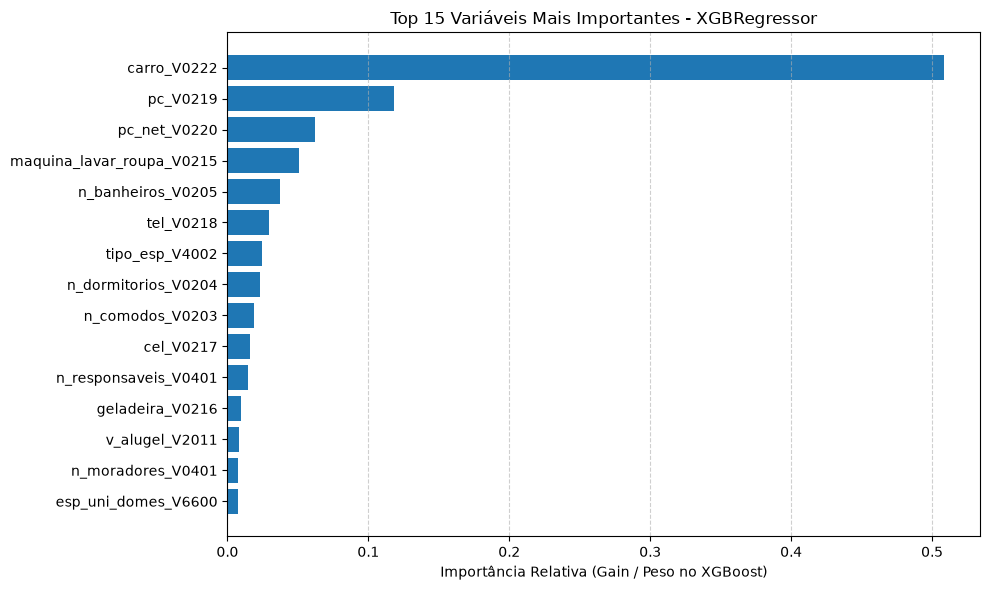

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Extrai a importância das features e organiza em um DataFrame
importancias = pd.DataFrame({
    'Feature': reg.feature_names_in_,
    'Importancia': reg.feature_importances_
}).sort_values(by='Importancia', ascending=True) # Ordena do menor para o maior para o gráfico horizontal

# 2. Filtra as Top 15 mais importantes (caso você tenha muitas colunas)
top_n = importancias.tail(15)

# 3. Cria o gráfico de barras horizontais
plt.figure(figsize=(10, 6))
plt.barh(top_n['Feature'], top_n['Importancia'], color='#1f77b4')
plt.xlabel('Importância Relativa (Gain / Peso no XGBoost)')
plt.title('Top 15 Variáveis Mais Importantes - XGBRegressor')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


Pensamento - Remoção de features com baixa importancia, para atenuar ruidos;

In [36]:
df.info()

<class 'pandas.DataFrame'>
Index: 43889 entries, 0 to 44501
Data columns (total 41 columns):
 #   Column                                 Non-Null Count  Dtype   
---  ------                                 --------------  -----   
 0   AREAP_V0011                            43889 non-null  category
 1   peso_V0010                             43889 non-null  int64   
 2   situacao_domicilio_V1006               43889 non-null  category
 3   especie_dom_V4001                      43889 non-null  category
 4   tipo_esp_V4002                         43889 non-null  category
 5   condicao_oculpacao_V0201               43889 non-null  category
 6   v_alugel_V2011                         43889 non-null  float64 
 7   v_alugel_sal_V2012                     43889 non-null  float64 
 8   mat_paredes_V0202                      43889 non-null  category
 9   n_comodos_V0203                        43889 non-null  int64   
 10  densidade_moradores_comodo__V6203      43889 non-null  int64   
 11  n_dor

In [37]:
import gc

# try:
#     del X_treino, X_test, y_treino, y_test , top_n    
#     gc.collect() 
# except KeyError:
#     pass

X_reduzido = X.drop(columns=importancias.head(22)['Feature'])

X_treino, X_test, y_treino, y_test = train_test_split(
    X_reduzido, Y, test_size=0.33, random_state=42)


X_train, X_val, y_train, y_val = train_test_split(X_treino, y_treino, test_size=0.2, random_state=42)





In [38]:
y_train.describe()

count    23524.000000
mean         6.921009
std          1.970454
min          0.000000
25%          6.417957
50%          7.163172
75%          7.905073
max         13.202100
Name: renda_V6529, dtype: float64

In [39]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 23524 entries, 25981 to 42793
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   tipo_esp_V4002             23524 non-null  category
 1   v_alugel_V2011             23524 non-null  float64 
 2   n_comodos_V0203            23524 non-null  int64   
 3   n_dormitorios_V0204        23524 non-null  int64   
 4   n_banheiros_V0205          23524 non-null  int64   
 5   maquina_lavar_roupa_V0215  23524 non-null  category
 6   geladeira_V0216            23524 non-null  category
 7   cel_V0217                  23524 non-null  category
 8   tel_V0218                  23524 non-null  category
 9   pc_V0219                   23524 non-null  category
 10  pc_net_V0220               23524 non-null  category
 11  carro_V0222                23524 non-null  category
 12  n_responsaveis_V0401       23524 non-null  int64   
dtypes: category(8), float64(1), int64(4)
memory

Pensamento - teste para observar se ouve perdar após a remoção das features

In [40]:

params = {
    'n_estimators': 6000, 
    'learning_rate': 0.05, 
    'max_depth': 6, 
    'objective':"reg:absoluteerror",
}
reg = XGBRegressor(
    enable_categorical=True,
    random_state=42,
    tree_method="hist",
    eval_metric="mphe",
    early_stopping_rounds=50,    
    **params
    
)

reg.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=100  # Mostra o progresso a cada 100 iterações (use False para ocultar)
)
y_pred_train = reg.predict(X_train)
y_pred_test = reg.predict(X_test)


[0]	validation_0-mphe:0.69767	validation_1-mphe:0.74466
[100]	validation_0-mphe:0.50520	validation_1-mphe:0.55844
[197]	validation_0-mphe:0.50112	validation_1-mphe:0.55803


In [41]:
avaliar_metricas(y_train, y_pred_train,  y_test,  y_pred_test) 

,Base,R²,MAE (R$),MAPE,MSE (R$²),RMSE (R$),D²
0,Treino (em R$),0.192178,1481.368634,3.222132e+17,4.583866e+07,6770.425261,0.309306
1,Teste (em R$),0.161458,1620.305215,3.104901e+17,6.179141e+07,7860.750994,0.285393


Pensamento - O modelo permaneceu estavél

Pensamento - 
- Remoção de Outliers para melhorar metricas R² que afetada diretamente;
- Aredondamento dos valores proximos a zero, para evitar os erros na MAPE

In [42]:
from scipy.stats import zscore

y_train_real = np.expm1(y_train)
# 1. Calcula o Z-score no y_train na escala REAL
z_scores = zscore(y_train_real, nan_policy='omit')

# 2. Pega o menor e o maior valor REAL que não são outliers (limite 4)
limite_inf = y_train_real[(z_scores >= -0.36) & (y_train_real > 0)].min()
# limite_sup = y_train_real[z_scores <= 12].max()

# 3. Substitui os 360 outliers pelos últimos valores válidos
y_train_tratado = y_train_real.clip(lower=limite_inf)

print(f"Novo mínimo: {y_train_tratado.min()}")
print(f"Novo máximo: {y_train_tratado.max()}")

Novo mínimo: 80.00000000000003
Novo máximo: 541499.9999999999


In [43]:
limite_sup = y_train_real[z_scores <12].max()

# 1. Quantidade absoluta
qtd_acima = (y_train_real > limite_sup).sum()

# 2. Percentual da base
pct_acima = (y_train_real > limite_sup).mean() * 100

print(f"Limite Superior: R$ {limite_sup:,.2f}")
print(f"Quantidade de registros acima: {qtd_acima}")
print(f"Percentual da base: {pct_acima:.2f}%")

Limite Superior: R$ 82,350.00
Quantidade de registros acima: 15
Percentual da base: 0.06%


In [44]:
y_train_tratado =np.log1p(y_train_tratado)

In [45]:
y_train_tratado.max()

np.float64(13.202100192143545)

In [46]:
params = {
    'n_estimators': 6000, 
    'learning_rate': 0.3, 
    'max_depth': 6, 
    'objective':"reg:absoluteerror",
}
reg = XGBRegressor(
    enable_categorical=True,
    random_state=42,
    tree_method="hist",
    eval_metric="mphe",
    early_stopping_rounds=50,    
    **params
    
)



reg.fit(
    X_train, y_train_tratado,
    eval_set=[(X_train, y_train_tratado), (X_val, y_val)],
    verbose=100  # Mostra o progresso a cada 100 iterações (use False para ocultar)
)
y_pred_train = reg.predict(X_train)
y_pred_test = reg.predict(X_test)
avaliar_metricas(y_train_tratado, y_pred_train, y_test , y_pred_test)

[0]	validation_0-mphe:0.39962	validation_1-mphe:0.68456
[77]	validation_0-mphe:0.26138	validation_1-mphe:0.55958


,Base,R²,MAE (R$),MAPE,MSE (R$²),RMSE (R$),D²
0,Treino (em R$),0.195324,1476.198678,1.475487e+00,4.563992e+07,6755.732173,0.310251
1,Teste (em R$),0.159739,1625.032771,3.173389e+17,6.191810e+07,7868.805643,0.283308


In [47]:
y_train_tratado.describe()

count    23524.000000
mean         7.165217
std          1.235464
min          4.394449
25%          6.417957
50%          7.163172
75%          7.905073
max         13.202100
Name: renda_V6529, dtype: float64

Pensamento- Os dados após serem Winsorization  pioram o modelo final.